## Feature Extraction Anatomica con Nilearn

### Estrazione delle metriche volumetriche delle Regioni di Interesse (ROI) dalle scansioni 3D MNI152 usando l'atlante anatomico Harvard-Oxford per integrarle nei modelli di Machine Learning

Dataset tabellare caricato: 436 soggetti
Download dell'atlante Harvard-Oxford...
[fetch_atlas_harvard_oxford] Dataset directory found: C:\Users\filip\nilearn_data\fsl
Indice Left Hippocampus: 9 (Left Hippocampus)
Indice Right Hippocampus: 19 (Right Hippocampus)


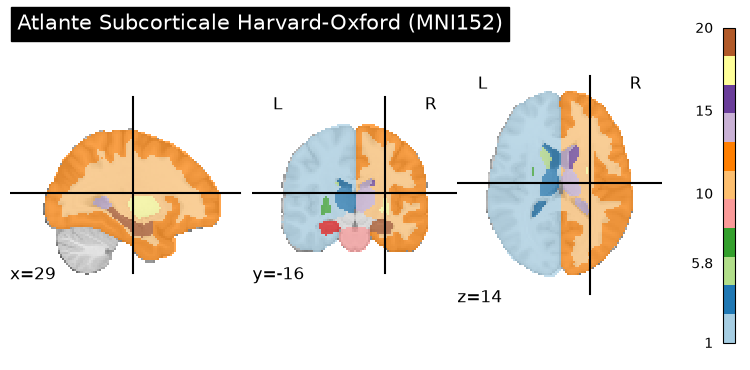

In [1]:
import os
import pandas as pd
import numpy as np
import nibabel as nib
from nilearn import datasets, image, plotting

# 1. Caricamento del dataset tabellare OASIS-1
csv_path = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/raw/oasis_cross-sectional-5708aa0a98d82080.csv"
df = pd.read_csv(csv_path)
print(f"Dataset tabellare caricato: {df.shape[0]} soggetti")

# 2. Download dell'atlante corticale e subcorticale Harvard-Oxford
print("Download dell'atlante Harvard-Oxford...")
atlas_sub = datasets.fetch_atlas_harvard_oxford('sub-maxprob-thr25-2mm')
atlas_filename = atlas_sub.maps
labels = atlas_sub.labels

# 3. Identifichiamo gli indici dell'Ippocampo (Left & Right Hippocampus)
left_hippo_idx = [i for i, label in enumerate(labels) if 'Left Hippocampus' in label][0]
right_hippo_idx = [i for i, label in enumerate(labels) if 'Right Hippocampus' in label][0]
print(f"Indice Left Hippocampus: {left_hippo_idx} ({labels[left_hippo_idx]})")
print(f"Indice Right Hippocampus: {right_hippo_idx} ({labels[right_hippo_idx]})")

# 4. Visualizziamo l'atlante per verificare la maschera subcorticale
plotting.plot_roi(
    atlas_filename,
    title="Atlante Subcorticale Harvard-Oxford (MNI152)",
    display_mode="ortho",
    cmap="Paired"
)
plotting.show()

### Estrazione del volume dell'Ippocampo per il soggetto di test

File trovato automaticamente: C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data\raw\disc1\OAS1_0001_MR1\RAW\OAS1_0001_MR1_mpr-1_anon.img


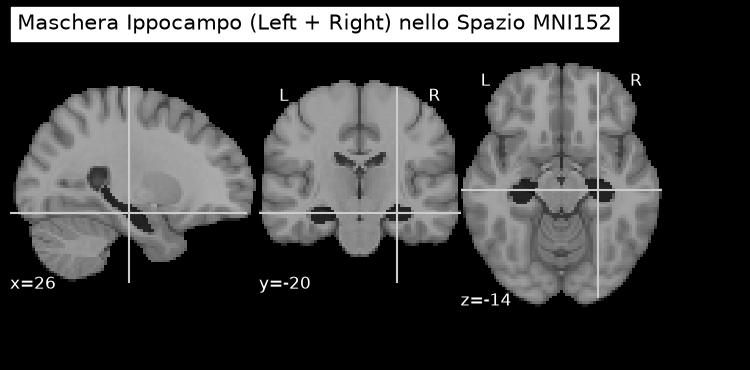

In [2]:
# 1. Definiamo il percorso al primo file MRI (OAS1_0001_MR1)
# Verificale e adatta la cartella data se necessario
data_dir = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data" 
target_file = os.path.join(data_dir, "OAS1_0001_MR1", "RAW", "OAS1_0001_MR1_mpr-1_anon.img")

# Se il file .img/.hdr non esiste in quel percorso, cerchiamo il primo disponibile
if not os.path.exists(target_file):
    import glob
    img_files = glob.glob(f"{data_dir}/**/RAW/*.img", recursive=True)
    if img_files:
        target_file = img_files[0]
        print(f"File trovato automaticamente: {target_file}")
    else:
        raise FileNotFoundError("Nessun file .img trovato nella cartella data!")

# 2. Carichiamo la mappa dell'atlante come oggetto NIfTI
atlas_img = image.load_img(atlas_filename)
atlas_data = atlas_img.get_fdata()

# 3. Creiamo una maschera booleana che isola solo l'Ippocampo (Sinistro + Destro)
hippo_mask_data = (atlas_data == left_hippo_idx) | (atlas_data == right_hippo_idx)
hippo_mask_img = nib.Nifti1Image(hippo_mask_data.astype(np.int32), affine=atlas_img.affine)

# 4. Visualizziamo la maschera dell'Ippocampo sovrapposta al template MNI152
mni_template = datasets.load_mni152_template(resolution=2)
plotting.plot_roi(
    hippo_mask_img,
    bg_img=mni_template,
    title="Maschera Ippocampo (Left + Right) nello Spazio MNI152",
    display_mode="ortho",
    cmap="gist_heat"
)
plotting.show()

In [3]:
# 5. Calcoliamo il volume dell'ippocampo in mm^3 per OAS1_0001_MR1
img_nib = nib.load(target_file)
img_canonical = nib.as_closest_canonical(img_nib)

img_resampled = image.resample_to_img(
    source_img=img_canonical,
    target_img=atlas_img
)

# Estraiamo i voxel all'interno della maschera dell'ippocampo
mri_data_resampled = img_resampled.get_fdata()
voxel_volume = np.abs(np.linalg.det(atlas_img.affine[:3, :3])) # Volume voxel in mm^3

# Calcoliamo il volume approssimativo della materia cerebrale nell'ippocampo
# consideriamo i voxel con intensità > 0 all'interno della maschera
hippo_voxels = mri_data_resampled[hippo_mask_data]
hippo_volume_mm3 = np.sum(hippo_voxels > 0) * voxel_volume

print(f"Volume calcolato dell'Ippocampo per OAS1_0001_MR1: {hippo_volume_mm3:.2f} mm³")

C:\Users\filip\AppData\Local\Temp\ipykernel_26524\3815894523.py:5: UserWarning: Casting data from int16 to float32
  img_resampled = image.resample_to_img(


Volume calcolato dell'Ippocampo per OAS1_0001_MR1: 11112.00 mm³


### Loop di estrazione automatica per tutti i soggetti

In [4]:
import glob
from tqdm import tqdm

def extract_hippocampus_volumes(data_directory, atlas_image, left_idx, right_idx):
    """
    Scorre tutte le scansioni nel dataset, registra su MNI ed estrae i volumi ippocampali 
    applicando una soglia d'intensità per isolare la sola materia grigia.
    """
    # Troviamo tutti i file .img nelle sottocartelle RAW
    search_pattern = os.path.join(data_directory, "**", "RAW", "*.img")
    subject_files = sorted(glob.glob(search_pattern, recursive=True))

    print(f"Trovate {len(subject_files)} scansioni 3D nel dataset.")

    # Prepariamo la maschera anatomica
    atlas_data = atlas_image.get_fdata()
    left_mask = (atlas_data == left_idx)
    right_mask = (atlas_data == right_idx)

    voxel_vol = np.abs(np.linalg.det(atlas_image.affine[:3, :3]))
    results = []

    for file_path in tqdm(subject_files, desc="Estrazione Feature ROI"):
        # Estraiamo l'ID del soggetto dal percorso (es. OAS1_0001_MR1)
        subject_id = os.path.basename(file_path).split('_mpr')[0]

        try:
            # Caricamento e allineamento canonico
            img_nib = nib.load(file_path)
            img_canonical = nib.as_closest_canonical(img_nib)

            # Ricampionamento sullo spazio dell'atlante
            img_resample = image.resample_to_img(
                source_img=img_canonical,
                target_img=atlas_image
            )

            mri_data = img_resample.get_fdata()
            if mri_data.ndim == 4:
                mri_data = mri_data[:, :, :, 0]

            # Calcolo soglia dinamica sul segnale cerebrale per escludere sfondi/liquidi
            nonzero_voxels = mri_data[mri_data > 0]
            if len(nonzero_voxels) > 0:
                intensity_threshold = np.percentile(nonzero_voxels, 35) # Soglia per isolare la materia grigia
            else:
                intensity_threshold = 0

            # Conteggio voxel reali di materia grigia nell'ippocampo
            vol_left = np.sum((mri_data > intensity_threshold) & left_mask) * voxel_vol
            vol_right = np.sum((mri_data > intensity_threshold) & right_mask) * voxel_vol
            vol_total = vol_left + vol_right

            results.append({
                'ID': subject_id,
                'Left_Hippo_Vol': vol_left,
                'Right_Hippo_Vol': vol_right,
                'Total_Hippo_Vol': vol_total
            })
        
        except Exception as e:
            print(f"Errore nell'elaborazione del soggetto {subject_id}: {e}")

    return pd.DataFrame(results)

# Eseguiamo l'estrazione con la correzione di soglia
df_roi_features = extract_hippocampus_volumes(data_dir, atlas_img, left_hippo_idx, right_hippo_idx)
print("\nPrime 5 righe delle feature esatte:")
print(df_roi_features.head())

Trovate 148 scansioni 3D nel dataset.


Estrazione Feature ROI:   0%|          | 0/148 [00:00<?, ?it/s]C:\Users\filip\AppData\Local\Temp\ipykernel_26524\2883360643.py:33: UserWarning: Casting data from int16 to float32
  img_resample = image.resample_to_img(
Estrazione Feature ROI:   1%|          | 1/148 [00:00<01:16,  1.93it/s]C:\Users\filip\AppData\Local\Temp\ipykernel_26524\2883360643.py:33: UserWarning: Casting data from int16 to float32
  img_resample = image.resample_to_img(
Estrazione Feature ROI:   1%|▏         | 2/148 [00:01<01:18,  1.86it/s]C:\Users\filip\AppData\Local\Temp\ipykernel_26524\2883360643.py:33: UserWarning: Casting data from int16 to float32
  img_resample = image.resample_to_img(
Estrazione Feature ROI:   2%|▏         | 3/148 [00:01<01:18,  1.85it/s]C:\Users\filip\AppData\Local\Temp\ipykernel_26524\2883360643.py:33: UserWarning: Casting data from int16 to float32
  img_resample = image.resample_to_img(
Estrazione Feature ROI:   3%|▎         | 4/148 [00:02<01:15,  1.91it/s]C:\Users\filip\AppData\Local\


Prime 5 righe delle feature esatte:
              ID  Left_Hippo_Vol  Right_Hippo_Vol  Total_Hippo_Vol
0  OAS1_0001_MR1          5256.0           5472.0          10728.0
1  OAS1_0001_MR1          5352.0           5512.0          10864.0
2  OAS1_0001_MR1          5272.0           5528.0          10800.0
3  OAS1_0001_MR1          5312.0           5544.0          10856.0
4  OAS1_0002_MR1          5296.0           5504.0          10800.0


### Unione con il DataFrame Tabellare (Merge)

In [5]:
# 1. Aggreghiamo per ID prendendo la media dei volumi tra le varie scansioni dello stesso soggetto
df_roi_clean = df_roi_features.groupby('ID', as_index=False).mean()
print(f"Soggetti unici con feature ROI: {len(df_roi_clean)}")

# 2. Carichiamo il CSV clinico specificando il separatore punto e virgola ';'
csv_path = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/raw/oasis_cross-sectional-5708aa0a98d82080.csv"
df_clinical = pd.read_csv(csv_path, sep=';')

# Pulizia dei nomi delle colonne
df_clinical.columns = df_clinical.columns.str.strip()

# 3. Uniamo i volumi dell'Ippocampo con le variabili cliniche usando la colonna 'ID'
df_combined = pd.merge(
    df_clinical, 
    df_roi_clean, 
    on='ID', 
    how='inner'
)

print(f"\nDataset finale pronto per il Machine Learning: {df_combined.shape[0]} soggetti e {df_combined.shape[1]} colonne.")

# 4. Salviamo il dataset arricchito
output_csv_path = "C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/oasis_features_hippocampus.csv"
df_combined.to_csv(output_csv_path, index=False)
print(f"Dataset salvato con successo in: {output_csv_path}")

# Visualizziamo le colonne cliniche principali unite ai volumi ippocampali
cols_to_show = [c for c in ['ID', 'Age', 'MMSE', 'CDR', 'Total_Hippo_Vol'] if c in df_combined.columns]
df_combined[cols_to_show].head()

Soggetti unici con feature ROI: 39

Dataset finale pronto per il Machine Learning: 39 soggetti e 15 colonne.
Dataset salvato con successo in: C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/oasis_features_hippocampus.csv


,ID,Age,MMSE,CDR,Total_Hippo_Vol
0,OAS1_0001_MR1,74,29.0,0.0,10812.0
1,OAS1_0002_MR1,55,29.0,0.0,10658.0
2,OAS1_0003_MR1,73,27.0,0.5,9956.0
3,OAS1_0004_MR1,28,NaN,NaN,10458.0
4,OAS1_0005_MR1,18,NaN,NaN,10640.0


### Verifica dell'effetto clinico (Atrofia Ippocampale vs CDR)

C:\Users\filip\AppData\Local\Temp\ipykernel_26524\1708169420.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_combined, x='CDR', y='Total_Hippo_Vol', palette='Set2')


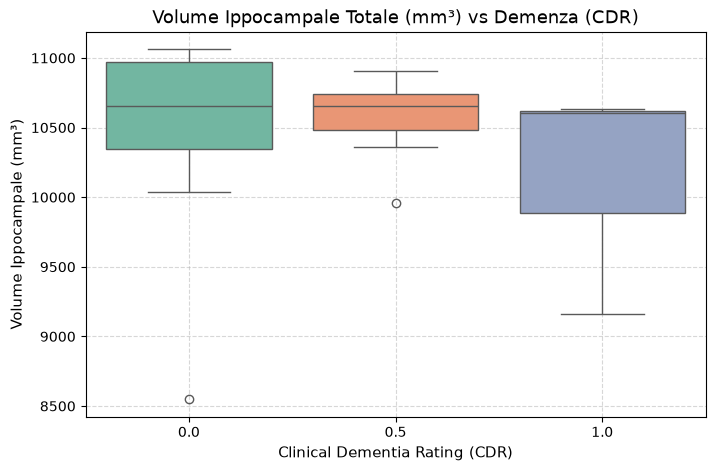

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_combined, x='CDR', y='Total_Hippo_Vol', palette='Set2')
plt.title('Volume Ippocampale Totale (mm³) vs Demenza (CDR)', fontsize=13)
plt.xlabel('Clinical Dementia Rating (CDR)', fontsize=11)
plt.ylabel('Volume Ippocampale (mm³)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Addestramento e Confronto con Random Forest / XGBoost

--- RISULTATI MACHINE LEARNING ---
Accuratezza Modello Baseline (Solo Dati Clinici): 85.71%
Accuratezza Modello Potenziato (+ Volume Ippocampale): 85.71%


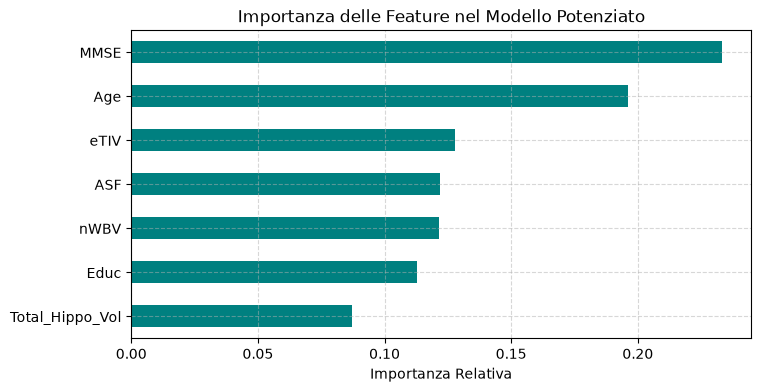

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Preparazione del target e binarizzazione CDR (0 = Sano, > 0 = Decadimento/Demenza)
df_ml = df_combined.dropna(subset=['CDR']).copy()
df_ml['Target'] = (df_ml['CDR'] > 0).astype(int)

# 2. Definizione delle feature per il confronto
baseline_features = [c for c in ['Age', 'Educ', 'MMSE', 'eTIV', 'nWBV', 'ASF'] if c in df_ml.columns]
enhanced_features = baseline_features + ['Total_Hippo_Vol']

X_base = df_ml[baseline_features].fillna(df_ml[baseline_features].median())
X_enh = df_ml[enhanced_features].fillna(df_ml[enhanced_features].median())
y = df_ml['Target']

# 3. Train/Test Split (stratificato per bilanciare le classi)
X_tr_b, X_te_b, y_train, y_test = train_test_split(X_base, y, test_size=0.25, random_state=42, stratify=y)
X_tr_e, X_te_e, _, _ = train_test_split(X_enh, y, test_size=0.25, random_state=42, stratify=y)

# 4. Modello Baseline (Senza Ippocampo)
rf_base = RandomForestClassifier(n_estimators=100, random_state=42)
rf_base.fit(X_tr_b, y_train)
acc_base = accuracy_score(y_test, rf_base.predict(X_te_b))

# 5. Modello Potenziato (Con Volume Ippocampale)
rf_enh = RandomForestClassifier(n_estimators=100, random_state=42)
rf_enh.fit(X_tr_e, y_train)
acc_enh = accuracy_score(y_test, rf_enh.predict(X_te_e))

print(f"--- RISULTATI MACHINE LEARNING ---")
print(f"Accuratezza Modello Baseline (Solo Dati Clinici): {acc_base * 100:.2f}%")
print(f"Accuratezza Modello Potenziato (+ Volume Ippocampale): {acc_enh * 100:.2f}%")

# 6. Feature Importance del modello potenziato
importances = pd.Series(rf_enh.feature_importances_, index=enhanced_features).sort_values(ascending=True)

plt.figure(figsize=(8,4))
importances.plot(kind='barh', color='teal')
plt.title('Importanza delle Feature nel Modello Potenziato')
plt.xlabel('Importanza Relativa')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()